Guiding question: What makes newer cars more expensive to insure, and how much of it is theft?

Data used: IBC How Cars Measure Up 2026 (about 5,800 vehicles), plus FSRA average premiums and Équité Association’s most-stolen vehicle lists.

Key findings:

* Repair costs are the main driver. Collision and property damage ratings climb from about 15 for 1998 models to 125–160 for recent ones, while the typical recent car is below average on theft. Premiums rose fastest in rural areas, not the theft-heavy GTA, which is consistent with repair costs affecting everyone.
* Theft stacks on cars that are already expensive. Only 27% of recent vehicles are high-theft, but two-thirds of those are also expensive to repair. So theft mostly makes costly cars even costlier.
* Toyota's are know to be reliable but are now the most stolen. Ranked by count, Toyota had the most high-theft models. Ranked by rate, Land Rover (95%) and luxury brands led.
* The pure theft tax is rare. Only 13 vehicles, mostly trucks and 4x4s like the Wrangler and Silverado, are cheap to insure on everything except theft.

Limitations:

* Ratings are claim cost indexes, not actual premiums, and the link to premiums is consistent with the findings but doesn’t prove cause.
* Comparing model years today mixes design with age. Older cars are worth less, are driven less, and may not carry collision coverage.
* 2026 models are excluded because their data is immature.
* Model variants are not weighted by popularity, and some vehicles appear twice under different brands, like the Chevrolet Silverado and GMC Sierra.
* The data shows which cars are stolen, but not why.

What I’d do next:

* Compare past HCMU editions to track how specific models’ ratings change over time.
* Add vehicle prices to separate a car’s value from how it was designed.


In [1]:
import pandas as pd
from google.colab import files
uploaded = files.upload()

Saving hcmu_e_2026 (1).xlsm to hcmu_e_2026 (1).xlsm


In [2]:
import os
print(os.listdir())

['.config', 'drive', 'hcmu_e_2026 (1).xlsm', 'sample_data']


In [3]:
file = "hcmu_e_2026 (1).xlsm"
sheets = pd.ExcelFile(file).sheet_names
print(sheets)

['Legend', '1998-2026 Model Years']


In [4]:
df = pd.read_excel(file, sheet_name="1998-2026 Model Years", header=None)
print(df.shape)
df.head(10)

(5839, 19)


/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,RELATIVE CLAIM COST INDEXES,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,THEFT RELATIVE CLAIM INDEX
2,Collision,NaN,Comp,NaN,DCPD,NaN,AB,NaN,Make,NaN,Model,NaN,Body Style,NaN,Model Year,NaN,Power Type,NaN,Theft Frequency
3,NaN,NaN,NaN,NaN,43.7,NaN,127.3,NaN,ACURA,NaN,1.6EL 4DR,NaN,4D,NaN,2000,NaN,Gasoline/Diesel,NaN,1
4,NaN,NaN,20.3,NaN,45.4,NaN,228.2,NaN,ACURA,NaN,1.7EL 4DR,NaN,4D,NaN,2001,NaN,Gasoline/Diesel,NaN,247.9
5,23.7,NaN,19.7,NaN,39.5,NaN,84.8,NaN,ACURA,NaN,1.7EL 4DR,NaN,4D,NaN,2002,NaN,Gasoline/Diesel,NaN,174.7
6,22.1,NaN,12.5,NaN,52.6,NaN,49.7,NaN,ACURA,NaN,1.7EL 4DR,NaN,4D,NaN,2003,NaN,Gasoline/Diesel,NaN,1
7,NaN,NaN,11.1,NaN,61.4,NaN,189.7,NaN,ACURA,NaN,1.7EL 4DR,NaN,4D,NaN,2004,NaN,Gasoline/Diesel,NaN,203.7
8,NaN,NaN,NaN,NaN,NaN,NaN,48.4,NaN,ACURA,NaN,3.2TL 4DR,NaN,4D,NaN,1999,NaN,Gasoline/Diesel,NaN,1
9,NaN,NaN,NaN,NaN,60.5,NaN,164.1,NaN,ACURA,NaN,3.2TL 4DR,NaN,4D,NaN,2000,NaN,Gasoline/Diesel,NaN,1


In [5]:
df = pd.read_excel(file, sheet_name="1998-2026 Model Years", header=2)
df = df.dropna(axis=1, how="all")
print(df.shape)
df.head()

(5836, 10)


/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


,Collision,Comp,DCPD,AB,Make,Model,Body Style,Model Year,Power Type,Theft Frequency
0,NaN,NaN,43.7,127.3,ACURA,1.6EL 4DR,4D,2000,Gasoline/Diesel,1.0
1,NaN,20.3,45.4,228.2,ACURA,1.7EL 4DR,4D,2001,Gasoline/Diesel,247.9
2,23.7,19.7,39.5,84.8,ACURA,1.7EL 4DR,4D,2002,Gasoline/Diesel,174.7
3,22.1,12.5,52.6,49.7,ACURA,1.7EL 4DR,4D,2003,Gasoline/Diesel,1.0
4,NaN,11.1,61.4,189.7,ACURA,1.7EL 4DR,4D,2004,Gasoline/Diesel,203.7


In [6]:
print(df.isna().sum())
df.describe()

Collision          855
Comp               444
DCPD               269
AB                  50
Make                 0
Model                0
Body Style           0
Model Year           0
Power Type           0
Theft Frequency      5
dtype: int64


,Collision,Comp,DCPD,AB,Model Year,Theft Frequency
count,4981.000000,5392.000000,5567.000000,5786.000000,5836.000000,5831.000000
mean,100.641899,109.096217,98.621394,96.728396,2013.319054,100.589213
std,64.008055,259.271590,72.849686,81.063417,6.671659,243.184194
min,3.800000,2.500000,3.700000,0.300000,1998.000000,1.000000
25%,54.200000,33.775000,44.300000,48.600000,2008.000000,1.000000
50%,89.900000,61.800000,82.200000,80.050000,2014.000000,43.400000
75%,129.400000,104.500000,130.300000,124.000000,2019.000000,116.300000
max,602.000000,5817.800000,639.300000,1723.500000,2026.000000,8248.000000


In [7]:
print((df["Theft Frequency"] == 1).sum())

legend = pd.read_excel(file, sheet_name="Legend", header=None)
legend

2170


,0,1
0,NaN,NaN
1,DEFINITIONS OF TERMS USED:,NaN
2,NaN,NaN
3,AB (Accident Benefits),NaN
4,NaN,A relative index based on the frequency of Acc...
5,NaN,NaN
6,Claim Cost,NaN
7,NaN,Average amount paid for insurance claims for e...
8,NaN,NaN
9,Collision,NaN


In [8]:
for text in legend[1].dropna():
    print(text)
    print()


A relative index based on the frequency of Accident Benefit (personal injury) claims

Average amount paid for insurance claims for each vehicle

A relative index based on the cost per vehicle for Collision insurance claims

A relative index based on the cost per vehicle for Comprehensive insurance claims (including theft)

A relative index based on the cost per vehicle for Direct Compensation Property Damage insurance claims

Type of vehicle:

2D = 2/3 doors

4D = 4/5 doors

PU = Pickup

SUV = Sport Utility Vehicle

VAN = Van

WGN = Wagon

A relative index based on the number of theft claims per vehicle insured under comprehensive coverage

Ratings are expressed in relative terms with 100 representing the average in each category.

This means a result of 122 is 22% above the average and a result of 87 is 13% below the average.

Lower numbers indicate more favourable ratings.

More than 120    (20% above the average)

Between 81 and 120 

Less than 81    (19% below the average)

Less th

In [9]:
df["theft_is_1"] = df["Theft Frequency"] == 1
df.groupby("Model Year")["theft_is_1"].mean().round(2)

,theft_is_1
Model Year,
1998,0.52
1999,0.62
2000,0.69
2001,0.63
2002,0.69
2003,0.63
2004,0.66
2005,0.63
2006,0.62


Data notes

Ratings are relative indexes: 100 = average, lower = better.
Blank ratings = fewer than 1,500 insured vehicles. Left blank, not filled in.
Theft Frequency of 1.0 = little or no theft claims (floor value). Kept as a valid value. Supported by its higher share in older model years.
2026 model year excluded from trends because the data is immature (too little time on the road).
Medians used instead of means because of extreme outliers.

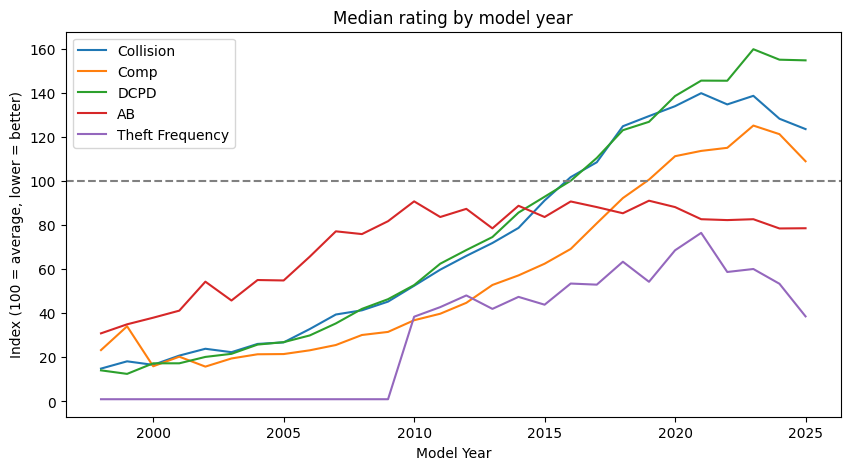

In [10]:
import matplotlib.pyplot as plt

ratings = ["Collision", "Comp", "DCPD", "AB", "Theft Frequency"]
trend = df[df["Model Year"] < 2026].groupby("Model Year")[ratings].median()

ax = trend.plot(figsize=(10, 5), title="Median rating by model year")
ax.axhline(100, color="grey", linestyle="--")
ax.set_ylabel("Index (100 = average, lower = better)")
plt.show()

1. Repair-related costs climb steeply for newer cars.
Collision, DCPD and Comp go from about 15 for 1998 models to about 125–160 for recent ones. DCPD (green) rises the most. Newer cars cost a lot more in claims.

2. Accident Benefits behave differently.
AB (red) rises until about 2010, then levels off below 100 and drifts down after 2019. Newer cars aren’t producing more injury claims. That fits the idea that safety tech helps people even as repair costs rise. This contrast is the “safer to crash in, more expensive to repair” story.

3. Theft (purple) is flat at 1 until 2009, then jumps.
That’s the 1.0 floor: for older years, more than half the cars sit at 1, so the median is 1. Theft risk rises for 2010+ models, peaks around 2021, then eases.

In [11]:
df["Body Style"].value_counts()

,count
Body Style,
SUV,2443
4D,1826
PU,714
2D,523
VAN,195
WGN,135


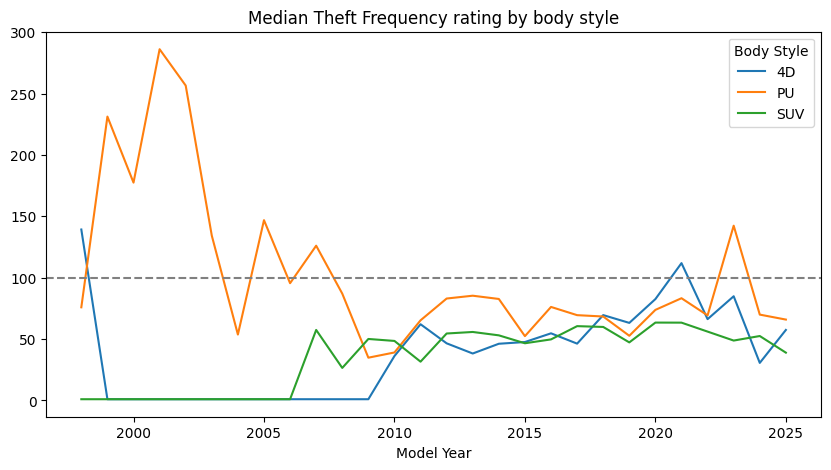

In [12]:
main_styles = ["SUV", "4D", "PU"]
subset = df[(df["Model Year"] < 2026) & (df["Body Style"].isin(main_styles))]

rating = "Theft Frequency"
pivot = subset.pivot_table(index="Model Year", columns="Body Style", values=rating, aggfunc="median")

ax = pivot.plot(figsize=(10, 5), title=f"Median {rating} rating by body style")
ax.axhline(100, color="grey", linestyle="--")
plt.show()

In [13]:
recent = df[(df["Model Year"] >= 2015) & (df["Model Year"] < 2026)]
cols = ["Make ", "Model", "Body Style", "Model Year", "Theft Frequency"]

recent.sort_values("Theft Frequency", ascending=False)[cols].head(15)

,Make,Model,Body Style,Model Year,Theft Frequency
3635,LEXUS,TX350 4DR AWD,SUV,2024,8248.0
5243,TOYOTA,GRAND HIGHLANDER HEV 4DR AWD,SUV,2024,4612.6
5513,TOYOTA,TUNDRA HEV 4WD,PU,2024,4220.7
5242,TOYOTA,GRAND HIGHLANDER 4DR AWD,SUV,2024,3760.4
5512,TOYOTA,TUNDRA HEV 4WD,PU,2023,3731.2
3631,LEXUS,RX500h 4DR AWD,SUV,2023,3351.8
3607,LEXUS,RX350h 4DR AWD,SUV,2023,3351.8
3605,LEXUS,RX350 4DR AWD,SUV,2023,3124.1
3606,LEXUS,RX350 4DR AWD,SUV,2024,2912.2
3608,LEXUS,RX350h 4DR AWD,SUV,2024,2691.6


In [14]:
df.columns = df.columns.str.strip()
print(df.columns.tolist())

['Collision', 'Comp', 'DCPD', 'AB', 'Make', 'Model', 'Body Style', 'Model Year', 'Power Type', 'Theft Frequency', 'theft_is_1']


In [15]:
red = recent[recent["Theft Frequency"] > 120]
print(len(red), "of", len(recent), "recent vehicles are red on theft")

red["Make "].value_counts().head(10)

719 of 2680 recent vehicles are red on theft


,count
Make,
TOYOTA,66
MERCEDES-BENZ,60
HONDA,60
LEXUS,56
FORD,50
BMW,48
GMC,35
LAND ROVER,35
CHEVROLET,34


In [16]:
recent = df[(df["Model Year"] >= 2015) & (df["Model Year"] < 2026)].copy()
recent["red_theft"] = recent["Theft Frequency"] > 120

share = recent.groupby("Make")["red_theft"].agg(["mean", "count"])
share[share["count"] >= 30].sort_values("mean", ascending=False).head(10)

,mean,count
Make,,
LAND ROVER,0.945946,37
ACURA,0.642857,42
MERCEDES-BENZ,0.600000,100
LEXUS,0.577320,97
RAM,0.542857,35
BMW,0.533333,90
DODGE,0.490566,53
HONDA,0.461538,130
INFINITI,0.406250,32


In [17]:
safe_but_stolen = recent[
    (recent["Collision"] < 81) &
    (recent["DCPD"] < 81) &
    (recent["AB"] < 81) &
    (recent["Theft Frequency"] > 120)
]
print(len(safe_but_stolen), "vehicles are green on Collision, DCPD and AB but red on theft")

cols = ["Make", "Model", "Model Year", "Collision", "DCPD", "AB", "Theft Frequency"]
safe_but_stolen.sort_values("Theft Frequency", ascending=False)[cols].head(15)

13 vehicles are green on Collision, DCPD and AB but red on theft


,Make,Model,Model Year,Collision,DCPD,AB,Theft Frequency
3197,JEEP,WRANGLER 4WD,2023,63.0,65.6,4.3,282.6
2206,GMC,SIERRA 1500 2WD,2016,55.9,60.5,7.9,215.2
954,CHEVROLET,SILVERADO 1500 2WD,2016,55.9,60.5,7.9,215.2
766,CHEVROLET,COLORADO 2WD,2016,66.6,72.6,27.6,197.3
2138,GMC,CANYON 2WD,2016,66.6,72.6,27.6,197.3
1792,FORD,F250 SD 4WD,2015,67.6,48.8,21.6,193.2
1793,FORD,F250 SD 4WD,2016,62.0,48.9,33.9,176.2
1795,FORD,F250 SD 4WD,2018,76.8,74.7,7.1,167.6
1004,CHEVROLET,SILVERADO 2500 4WD,2015,79.4,49.3,33.0,161.1
2256,GMC,SIERRA 2500 4WD,2015,79.4,49.3,33.0,161.1


The GMC Sierra and Chevy Silverado have identical numbers, and so do the Colorado and Canyon. They’re the same truck sold under two brands, and IBC rates them together. So the 13 rows are really closer to 9 unique vehicles.

In [18]:
top_theft = recent.sort_values("Theft Frequency", ascending=False).head(15)
top_theft[cols]

,Make,Model,Model Year,Collision,DCPD,AB,Theft Frequency
3635,LEXUS,TX350 4DR AWD,2024,133.7,237.7,112.7,8248.0
5243,TOYOTA,GRAND HIGHLANDER HEV 4DR AWD,2024,142.0,221.4,163.9,4612.6
5513,TOYOTA,TUNDRA HEV 4WD,2024,161.4,167.2,87.6,4220.7
5242,TOYOTA,GRAND HIGHLANDER 4DR AWD,2024,170.5,203.5,125.7,3760.4
5512,TOYOTA,TUNDRA HEV 4WD,2023,124.1,127.2,74.7,3731.2
3631,LEXUS,RX500h 4DR AWD,2023,147.9,249.1,123.9,3351.8
3607,LEXUS,RX350h 4DR AWD,2023,147.9,249.1,123.9,3351.8
3605,LEXUS,RX350 4DR AWD,2023,160.5,159.3,179.4,3124.1
3606,LEXUS,RX350 4DR AWD,2024,140.4,166.3,121.6,2912.2
3608,LEXUS,RX350h 4DR AWD,2024,150.3,258.7,127.5,2691.6


What happens to ratings as cars get newer
As cars get newer, insurance claim costs are increasing, mainly because they’re more expensive to repair. Collision, DCPD and Comp ratings climb from around 15 for 1998 models to 125–160 for recent ones. However, injury claims (AB) have stayed below average and haven’t risen the same way, which suggests safety features are helping. One caveat: this compares model years as they are today, so older cars also look cheaper because they’re worth less, are driven less, and may not carry collision coverage, not only because they were built differently.

What I found about theft
Theft isn’t spread evenly. Most cars are relatively safe, but a small group of trucks and SUVs are at the extreme end. For example, the 2024 Lexus TX350 has a theft index of 8,248, about 82 times the average. Overall, 27% of recent vehicles are red on theft, and when you compare brands by rate instead of count, luxury brands lead, with 95% of recent Land Rover models rated red.

The two forms of the theft tax
There are two kinds of theft tax. The first is the pure theft tax: pickups and 4x4s such as the Jeep Wrangler, Chevy Silverado and Ford F-250 are highly stolen but rate well on everything else. Only 13 recent vehicles fit this profile. The second is theft on top of everything: new luxury SUVs such as the Lexus TX and RX, Toyota Grand Highlander and Land Rover Defender. They’re already expensive to repair, and extreme theft risk piles on top of that.

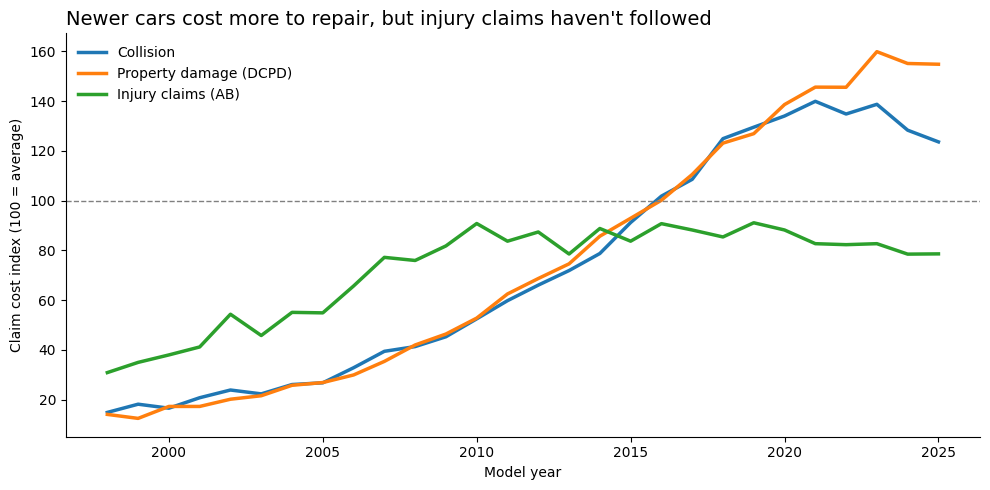

In [19]:
trend_cols = ["Collision", "DCPD", "AB"]

ax = trend[trend_cols].plot(figsize=(10, 5), linewidth=2.5)
ax.axhline(100, color="grey", linestyle="--", linewidth=1)

ax.set_title("Newer cars cost more to repair, but injury claims haven't followed", fontsize=14, loc="left")
ax.set_xlabel("Model year")
ax.set_ylabel("Claim cost index (100 = average)")
ax.legend(["Collision", "Property damage (DCPD)", "Injury claims (AB)"], frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("chart1_trends.png", dpi=200)
plt.show()

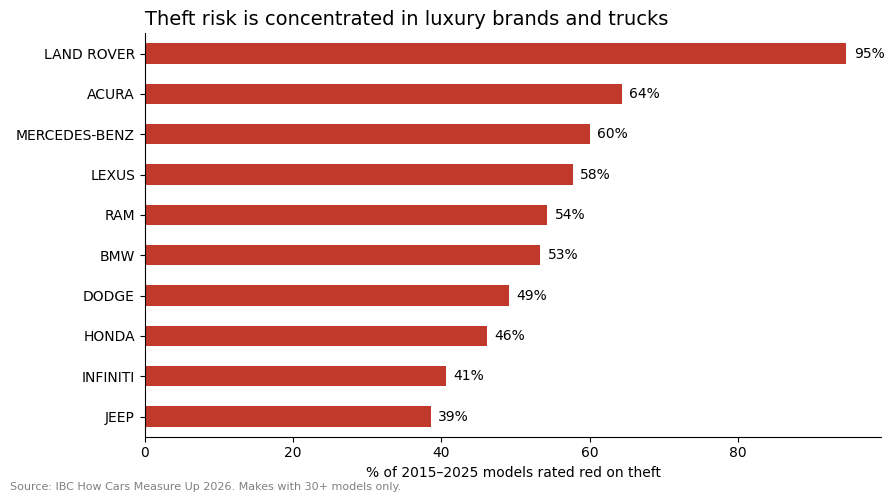

In [20]:
top_makes = share[share["count"] >= 30].sort_values("mean").tail(10)
pct = top_makes["mean"] * 100

ax = pct.plot(kind="barh", figsize=(9, 5), color="#C0392B")
ax.set_title("Theft risk is concentrated in luxury brands and trucks", fontsize=14, loc="left")
ax.set_xlabel("% of 2015–2025 models rated red on theft")
ax.set_ylabel("")
ax.spines[["top", "right"]].set_visible(False)

for i, v in enumerate(pct):
    ax.text(v + 1, i, f"{v:.0f}%", va="center")

plt.figtext(0.01, 0.01, "Source: IBC How Cars Measure Up 2026. Makes with 30+ models only.", fontsize=8, color="grey")
plt.tight_layout()
plt.savefig("chart2_theft_by_make.png", dpi=200)
plt.show()

13 pure theft tax | 472 theft on top of everything


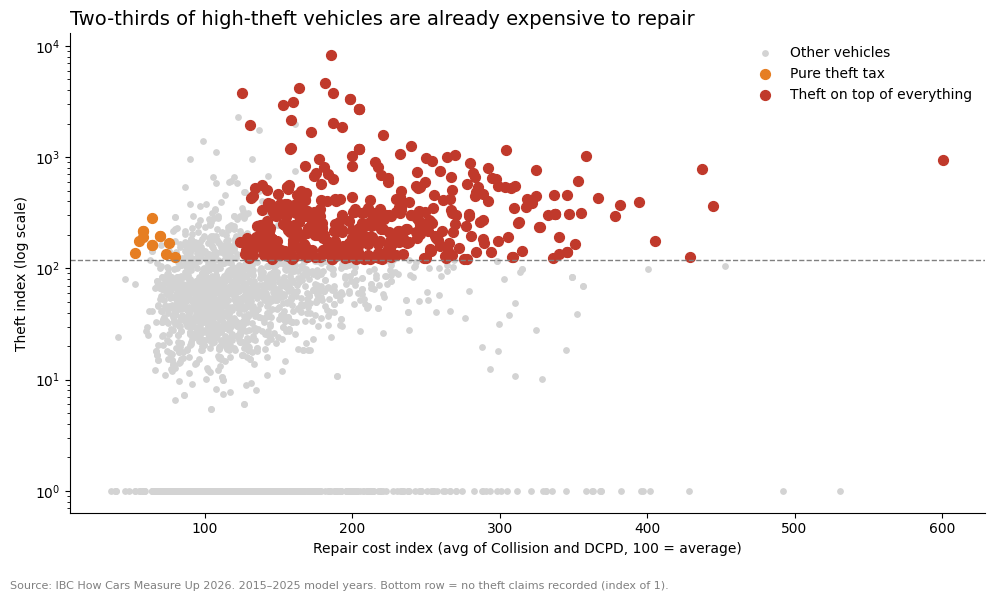

In [24]:
 plot_df = recent.dropna(subset=["Collision", "DCPD", "AB", "Theft Frequency"]).copy()
plot_df["repair"] = plot_df[["Collision", "DCPD"]].mean(axis=1)

pure = (plot_df["Collision"] < 81) & (plot_df["DCPD"] < 81) & (plot_df["AB"] < 81) & (plot_df["Theft Frequency"] > 120)
on_top = (plot_df["Collision"] > 120) & (plot_df["DCPD"] > 120) & (plot_df["Theft Frequency"] > 120)
print(pure.sum(), "pure theft tax |", on_top.sum(), "theft on top of everything")

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(plot_df["repair"], plot_df["Theft Frequency"], color="lightgrey", s=15, label="Other vehicles")
ax.scatter(plot_df.loc[pure, "repair"], plot_df.loc[pure, "Theft Frequency"], color="#E67E22", s=50, label="Pure theft tax")
ax.scatter(plot_df.loc[on_top, "repair"], plot_df.loc[on_top, "Theft Frequency"], color="#C0392B", s=50, label="Theft on top of everything")

ax.set_yscale("log")
ax.axhline(120, color="grey", linestyle="--", linewidth=1)
ax.set_title("Two-thirds of high-theft vehicles are already expensive to repair", fontsize=14, loc="left")
ax.set_xlabel("Repair cost index (avg of Collision and DCPD, 100 = average)")
ax.set_ylabel("Theft index (log scale)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.figtext(0.01, 0.01, "Source: IBC How Cars Measure Up 2026. 2015–2025 model years. Bottom row = no theft claims recorded (index of 1).", fontsize=8, color="grey")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("chart3_two_theft_taxes.png", dpi=200)
plt.show()

In [22]:
high_theft = plot_df["Theft Frequency"] > 120
print(round(on_top.sum() / high_theft.sum() * 100), "% of high-theft vehicles are also expensive to repair")

plot_df.loc[on_top, "Body Style"].value_counts()

67 % of high-theft vehicles are also expensive to repair


,count
Body Style,
SUV,227
4D,193
2D,34
PU,15
VAN,3


In [25]:
premiums = pd.DataFrame({
    "Date": ["Oct 2024", "Jun 2025", "Oct 2025", "Jun 2026"],
    "Ontario": [2006, 2120, 2164, 2218],
    "GTA": [2638, 2765, 2810, 2868],
    "Other Urban": [1918, 2031, 2076, 2131],
    "Rural": [1592, 1698, 1740, 1791],
})
premiums

,Date,Ontario,GTA,Other Urban,Rural
0,Oct 2024,2006,2638,1918,1592
1,Jun 2025,2120,2765,2031,1698
2,Oct 2025,2164,2810,2076,1740
3,Jun 2026,2218,2868,2131,1791


In [28]:
change = (premiums.iloc[-1, 1:] / premiums.iloc[0, 1:] - 1) * 100
change.astype(float).round(1)

,0
Ontario,10.6
GTA,8.7
Other Urban,11.1
Rural,12.5


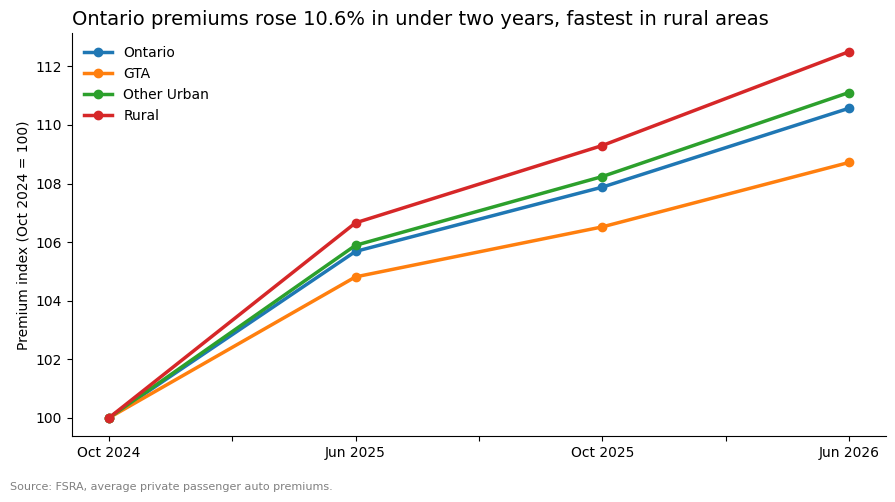

In [34]:
indexed = premiums.set_index("Date")
indexed = indexed / indexed.iloc[0] * 100

ax = indexed.plot(figsize=(9, 5), linewidth=2.5, marker="o")
ax.set_title("Ontario premiums rose 10.6% in under two years, fastest in rural areas", fontsize=14, loc="left")
ax.set_ylabel("Premium index (Oct 2024 = 100)")
ax.set_xlabel("")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.figtext(0.01, 0.01, "Source: FSRA, average private passenger auto premiums.", fontsize=8, color="grey")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("chart4_premiums.png", dpi=200)
plt.show()